<a href="https://colab.research.google.com/github/jess22jess/SIMULACI-N-II/blob/main/Modelo_SIR_PyMC.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Modelo SIR con pyMC

---

Arcos Gutiérrez Jessica Beatriz

---

Abordamos el problema inverso del modelo SIR utilizando los datos del brote de influenza en un internado. Nuestro objetivo es estimar las tasas de transmisión *alfa* y recuperación *beta* mediante inferencia bayesiana en PyMC, lo que permite obtener la distribución de probabilidad de los parámetros y cuantificar su incertidumbre.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import pymc as pm
import arviz as az
from scipy.integrate import odeint
import warnings

warnings.filterwarnings("ignore")

Población N = 763, iniciando con 1 infectado y 762 susceptibles.

Se programó la función con el sistema de ecuaciones diferenciales acopladas del modelo SIR y se configuró el solucionador numérico de PyMC.


In [3]:
t_data = np.arange(0, 15)
I_data = np.array([1, 3, 6, 25, 73, 222, 294, 258, 237, 191, 125, 69, 27, 11, 4])

N = 763
S0 = N - I_data[0]
I0 = I_data[0]

def SIR(y, t, p):
    a = p[0]
    b = p[1]
    ds = -a * y[0] * y[1]
    di = a * y[0] * y[1] - b * y[1]
    return [ds, di]

ode_model = pm.ode.DifferentialEquation(
    func=SIR,
    times=t_data,
    n_states=2,
    n_theta=2,
    t0=0,
)

Se definieron las distribuciones a priori como: Uniforme para alfa y beta, y Half-Normal para el error sigma.

In [4]:
with pm.Model() as model:
    a = pm.Uniform("a", lower=0, upper=0.01)
    b = pm.Uniform("b", lower=0, upper=1.0)
    sigma = pm.HalfNormal("sigma", sigma=10)

    sir_curves = ode_model(y0=[S0, I0], theta=[a, b])

    Y = pm.Normal("Y", mu=sir_curves[:, 1], sigma=sigma, observed=I_data)

Se ejecutó el muestreo MCMC con el algoritmo NUTS usando 5 cadenas independientes y 3000 muestras por cadena. Se ajustó target_accept=0.95 para evitar divergencias. La tabla resultante muestra las medias posteriores y el estadístico r_hat para verificar la convergencia.

In [7]:
with model:
    trace = pm.sample(
        draws=300,
        tune=300,
        chains=4,
        cores=1,
        target_accept=0.95,
        return_inferencedata=True
    )

print("\n--- RESUMEN ESTADÍSTICO ---")
print(az.summary(trace, var_names=["a", "b", "sigma"]))

Output()


--- RESUMEN ESTADÍSTICO ---
         mean     sd  hdi_3%  hdi_97%  mcse_mean  mcse_sd  ess_bulk  ess_tail  \
a       0.002  0.000   0.002    0.002      0.000    0.000     821.0     624.0   
b       0.447  0.015   0.418    0.476      0.001    0.001     721.0     495.0   
sigma  18.028  3.067  12.533   23.262      0.125    0.116     638.0     727.0   

       r_hat  
a       1.01  
b       1.00  
sigma   1.00  


La gráfica de distribución conjunta muestra las combinaciones probables de alfa y beta, donde las elipses representan los intervalos de credibilidad.

Finalmente, se simulan 100 curvas con parámetros muestreados y se superponen a los datos reales para validar el ajuste del modelo.

In [19]:
import matplotlib.patches as patches
from matplotlib.patches import Ellipse

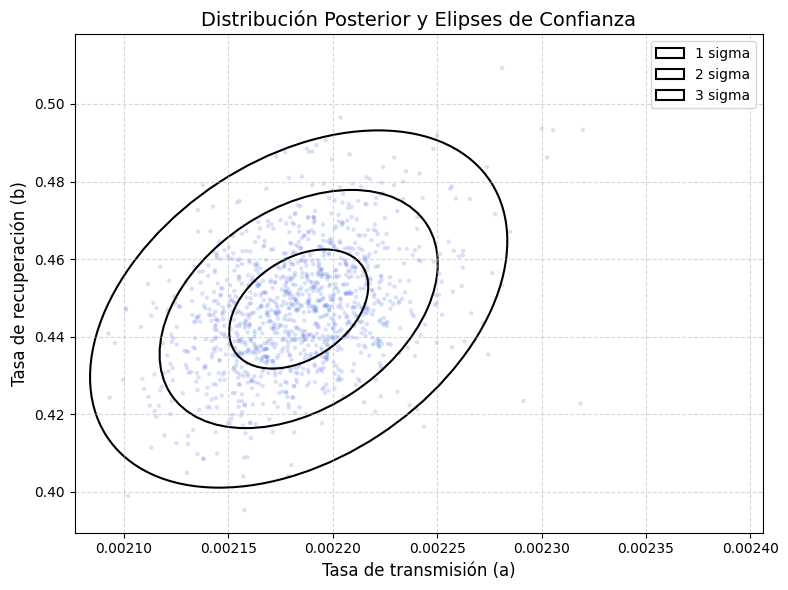

In [22]:
fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(a_samples, b_samples, alpha=0.2, color='royalblue', s=10, edgecolor='none')
media_a, media_b = np.mean(a_samples), np.mean(b_samples)
cov = np.cov(a_samples, b_samples)
vals, vecs = np.linalg.eigh(cov)
orden = vals.argsort()[::-1]
vals, vecs = vals[orden], vecs[:, orden]
angulo = np.degrees(np.arctan2(*vecs[:, 0][::-1]))

for i in [1, 2, 3]:
    ancho, alto = 2 * i * np.sqrt(vals)
    elipse = Ellipse(
        xy=(media_a, media_b),
        width=ancho,
        height=alto,
        angle=angulo,
        edgecolor='black',
        facecolor='none',
        linewidth=1.5,
        label=f'{i} sigma'
    )
    ax.add_patch(elipse)
    ax.set_xlabel('Tasa de transmisión (a)', fontsize=12)
ax.set_ylabel('Tasa de recuperación (b)', fontsize=12)
ax.set_title("Distribución Posterior y Elipses de Confianza", fontsize=14)
ax.legend(loc='upper right')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

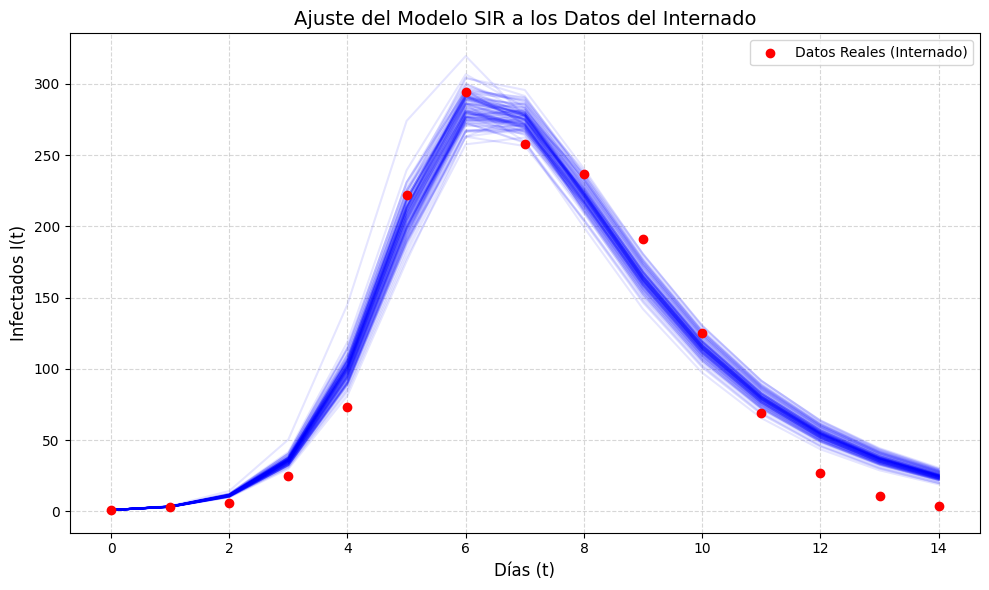

In [23]:
plt.figure(figsize=(10, 6))
plt.scatter(t_data, I_data, color='red', label='Datos Reales (Internado)', zorder=5)
for i in np.random.randint(0, len(a_samples), 100):
    sol = odeint(SIR, y0=[S0, I0], t=t_data, args=([a_samples[i], b_samples[i]],))
    plt.plot(t_data, sol[:, 1], color='blue', alpha=0.1)
plt.title("Ajuste del Modelo SIR a los Datos del Internado", fontsize=14)
plt.xlabel("Días (t)", fontsize=12)
plt.ylabel("Infectados I(t)", fontsize=12)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()